# LAB 3 - Bài 6 (Trang 26): Giảm số màu ảnh bằng k-Means
Hồng Kim Dung - 6451071009

**Lưu ý:** upload file ảnh `dog.png` lên Colab trước khi chạy.

## Khai báo thư viện

In [1]:
print("Hồng Kim Dung - 6451071009")
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
import os

Hồng Kim Dung - 6451071009


## Đọc file ảnh và hiển thị

Hồng Kim Dung - 6451071009


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


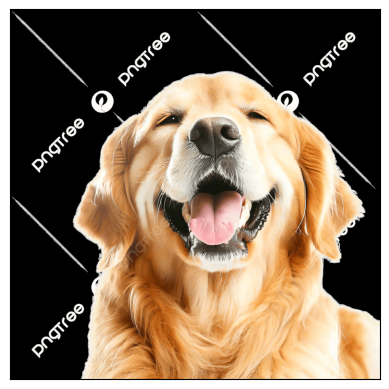

In [2]:
print("Hồng Kim Dung - 6451071009")
# Upload file dog.png lên Colab (biểu tượng thư mục bên trái) trước khi chạy.
# Muốn dùng ảnh khác thì đổi tên file ở dòng dưới.
image = Image.open("dog.png").convert("RGB")     # convert RGB để đảm bảo ảnh có đúng 3 kênh màu
axes = plt.axes(xticks=[], yticks=[])
axes.imshow(image)
plt.show()

## Chuyển ảnh thành mảng số, lấy chiều cao và chiều rộng

In [3]:
print("Hồng Kim Dung - 6451071009")
imarr = np.array(image)
rows = imarr.shape[0]
cols = imarr.shape[1]
print("Kích thước ảnh (cao, rộng, kênh):", imarr.shape)

Hồng Kim Dung - 6451071009
Kích thước ảnh (cao, rộng, kênh): (1200, 1200, 3)


## Chuẩn hóa về [0,1] và đổi mảng 3 chiều thành 2 chiều

In [4]:
print("Hồng Kim Dung - 6451071009")
data = imarr / 255.0          # đưa về thang 0...1
data = data.reshape(rows * cols, 3)
print(data.shape)

Hồng Kim Dung - 6451071009
(1440000, 3)


## Gom cụm k-Means với 32 màu

In [5]:
print("Hồng Kim Dung - 6451071009")
kmeans = KMeans(n_clusters=32, max_iter=300, n_init=3, random_state=42)
kmeans.fit(data)
new_colors = kmeans.cluster_centers_[kmeans.predict(data)]
print("Số màu sau khi gom cụm:", len(kmeans.cluster_centers_))

Hồng Kim Dung - 6451071009
Số màu sau khi gom cụm: 32


## Khôi phục dạng mảng 3 chiều

In [6]:
print("Hồng Kim Dung - 6451071009")
img_recolored = new_colors.reshape(imarr.shape)

Hồng Kim Dung - 6451071009


## So sánh ảnh gốc và ảnh 32 màu

Hồng Kim Dung - 6451071009


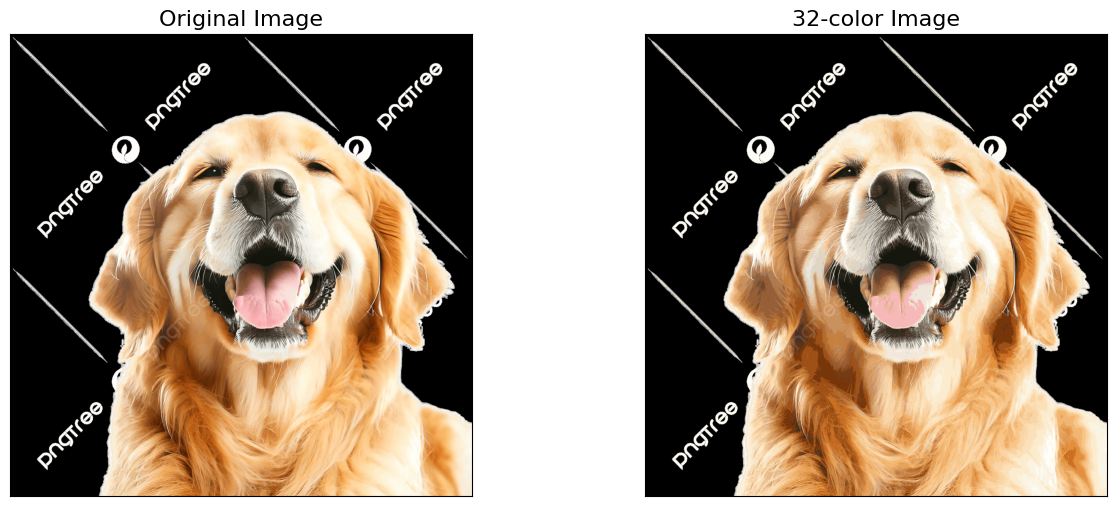

In [7]:
print("Hồng Kim Dung - 6451071009")
fig, ax = plt.subplots(1, 2, figsize=(16, 6),
                       subplot_kw=dict(xticks=[], yticks=[]))
fig.subplots_adjust(wspace=0.05)
ax[0].imshow(image)
ax[0].set_title("Original Image", size=16)
ax[1].imshow(img_recolored)
ax[1].set_title("32-color Image", size=16)
plt.show()

## Lưu ảnh kết quả xuống đĩa và so sánh dung lượng

In [8]:
print("Hồng Kim Dung - 6451071009")
img_recolored = img_recolored * 255
new_img = Image.fromarray(img_recolored.astype(np.uint8))
new_img.save("compressed_img2.png")

print("Ảnh gốc    :", os.path.getsize("dog.png") / 1024, "KB")
print("Ảnh 32 màu :", os.path.getsize("compressed_img2.png") / 1024, "KB")

Hồng Kim Dung - 6451071009
Ảnh gốc    : 419.7001953125 KB
Ảnh 32 màu : 475.12109375 KB


## Mở rộng - Lưu dạng bảng màu (palette) để giảm dung lượng rõ rệt

In [9]:
print("Hồng Kim Dung - 6451071009")
# Ảnh chỉ còn 32 màu nên có thể lưu dạng palette (mỗi pixel chỉ cần 1 chỉ số màu thay vì 3 giá trị RGB)
labels = kmeans.predict(data).reshape(rows, cols).astype(np.uint8)
palette = (kmeans.cluster_centers_ * 255).astype(np.uint8)

img_p = Image.fromarray(labels, mode="P")
img_p.putpalette(palette.flatten().tolist())
img_p.save("compressed_img2_palette.png", optimize=True)

print("Ảnh gốc          :", os.path.getsize("dog.png") / 1024, "KB")
print("Ảnh 32 màu (RGB) :", os.path.getsize("compressed_img2.png") / 1024, "KB")
print("Ảnh 32 màu (P)   :", os.path.getsize("compressed_img2_palette.png") / 1024, "KB")

Hồng Kim Dung - 6451071009


/tmp/ipykernel_1167/1957127779.py:6: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img_p = Image.fromarray(labels, mode="P")


Ảnh gốc          : 419.7001953125 KB
Ảnh 32 màu (RGB) : 475.12109375 KB
Ảnh 32 màu (P)   : 222.3916015625 KB
